<center><h1>Batra_Raghav_HW4</h1></center>
<br>
<br>

Name: Raghav Batra
<br>
Github Username: rbatra02
<br>
USC ID: 3227519293

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [66]:
import pandas as pd, glob, os, re
import numpy as np
from scipy import stats

Get the AReM Data Set

In [67]:
DATA_DIR = "../AReM"

COLS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def load_file(path):
    return pd.read_csv(path, comment="#", header=None, names=COLS, usecols=range(7), sep=r"[,\s]+", engine="python")

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

data = {}

for act in ACTIVITIES: 
    for path in glob.glob(os.path.join(DATA_DIR, act, "dataset*.csv")):
        n = int(re.search(r"dataset(\d+)", path).group(1))
        data[(act, n)] = load_file(path)


print(len(data))
print(sum(df.isna().sum().sum() for df in data.values()))
print({k: len(v) for k, v in data.items() if len(v) != 480})

88
0
{('sitting', 8): 479}


### (b) Splitting Data

In [68]:
train, test = {}, {}

for(act, n), df in data.items():
    if act in ("bending1", "bending2"):
        test_ids = {1,2}
    else:
        test_ids = {1,2,3}
    if n in test_ids:
        test[(act, n)] = df
    else:
        train[(act,n)] = df

print(len(train), len(test))

69 19


### (c) Feature Extraction

Statistical/Distribution
- min/max
- mean, median, mode
- standard deviation, variance
- range 
- first and third quartile, IQR
- percentiles
- skewness
- kurtosis

Energy/ magnitude
- root mean quare
- signal energy (sum of squared values)
- mean absolute value
- peak to peak amplitude

temporal structure
- autocorrelation
- zero crossing rate or mean crossing rate
- number of peaks
- slope or linear trend
- mean absolute difference between consecutive points

complexity
-entropy (sample entropy or approximate entropy)


In [69]:
#Extraction
SERIES = COLS[1:]
def extract_features(df):
    row = {}
    for i, col in enumerate(SERIES, start=1):
        s = df[col]
        row[f"min{i}"] = s.min()
        row[f"max{i}"] = s.max()
        row[f"mean{i}"] = s.mean()
        row[f"median{i}"] = s.median()
        row[f"std{i}"] = s.std()
        row[f"1st_quart{i}"] = s.quantile(0.25)
        row[f"3rd_quart{i}"] = s.quantile(0.75)
    return row

rows = []
for (act, n), df in sorted(data.items()):
    r = {"activity": act, "file": n, "split": "test" if (act,n) in test else "train"}
    r.update(extract_features(df))
    rows.append(r)

features = pd.DataFrame(rows)
features.index = range(1, len(features) + 1)
features.index.name = "Instance"

print(features.shape)
features.head()

feature_cols = features.columns[3:]
train_df = features[features.split == "train"]
test_df = features[features.split == "test"]


#Standard Deviation 
X = features[feature_cols].to_numpy()
n_rows = len(X)

rng = np.random.default_rng(42)
B = 1000
boot_stds = np.zeros((B, X.shape[1]))

for b in range(B):
    idx = rng.integers(0, n_rows, size=n_rows)
    boot_stds[b] = X[idx].std(axis=0, ddof=1)

ci = pd.DataFrame({
    "std": X.std(axis=0, ddof = 1),
    "CI_lower (5%)": np.percentile(boot_stds, 5, axis=0),
    "CI_upper (95%)": np.percentile(boot_stds, 95, axis=0),
}, index=feature_cols)

ci.round(3)

(88, 45)


,std,CI_lower (5%),CI_upper (95%)
min1,9.570,8.210,10.787
max1,4.394,3.327,5.322
mean1,5.336,4.722,5.899
median1,5.440,4.785,6.003
std1,1.772,1.569,1.944
1st_quart1,6.154,5.597,6.665
3rd_quart1,5.139,4.334,5.843
min2,0.000,0.000,0.000
max2,5.063,4.645,5.398
mean2,1.574,1.394,1.702


In [70]:
#Feature Selection 
train_df = features[features.split == "train"]
scores = {}
for ft in ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]:
    fs = []
    for k in range(1,7):
        col = f"{ft}{k}"
        if train_df[col].nunique() > 1:
            groups = [g[col] for _,g in train_df.groupby("activity")]
            fs.append(stats.f_oneway(*groups).statistic)
    scores[ft] = np.mean(fs)

pd.Series(scores).sort_values(ascending=False).round(1)

mean         368.2
3rd_quart    350.4
median       317.7
1st_quart    154.1
std          109.2
max           30.0
min           14.6
dtype: float64

mean, 3rd quartile and median have the largest f-scores.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score


#### i. Plots

class
other      60
bending     9
Name: count, dtype: int64


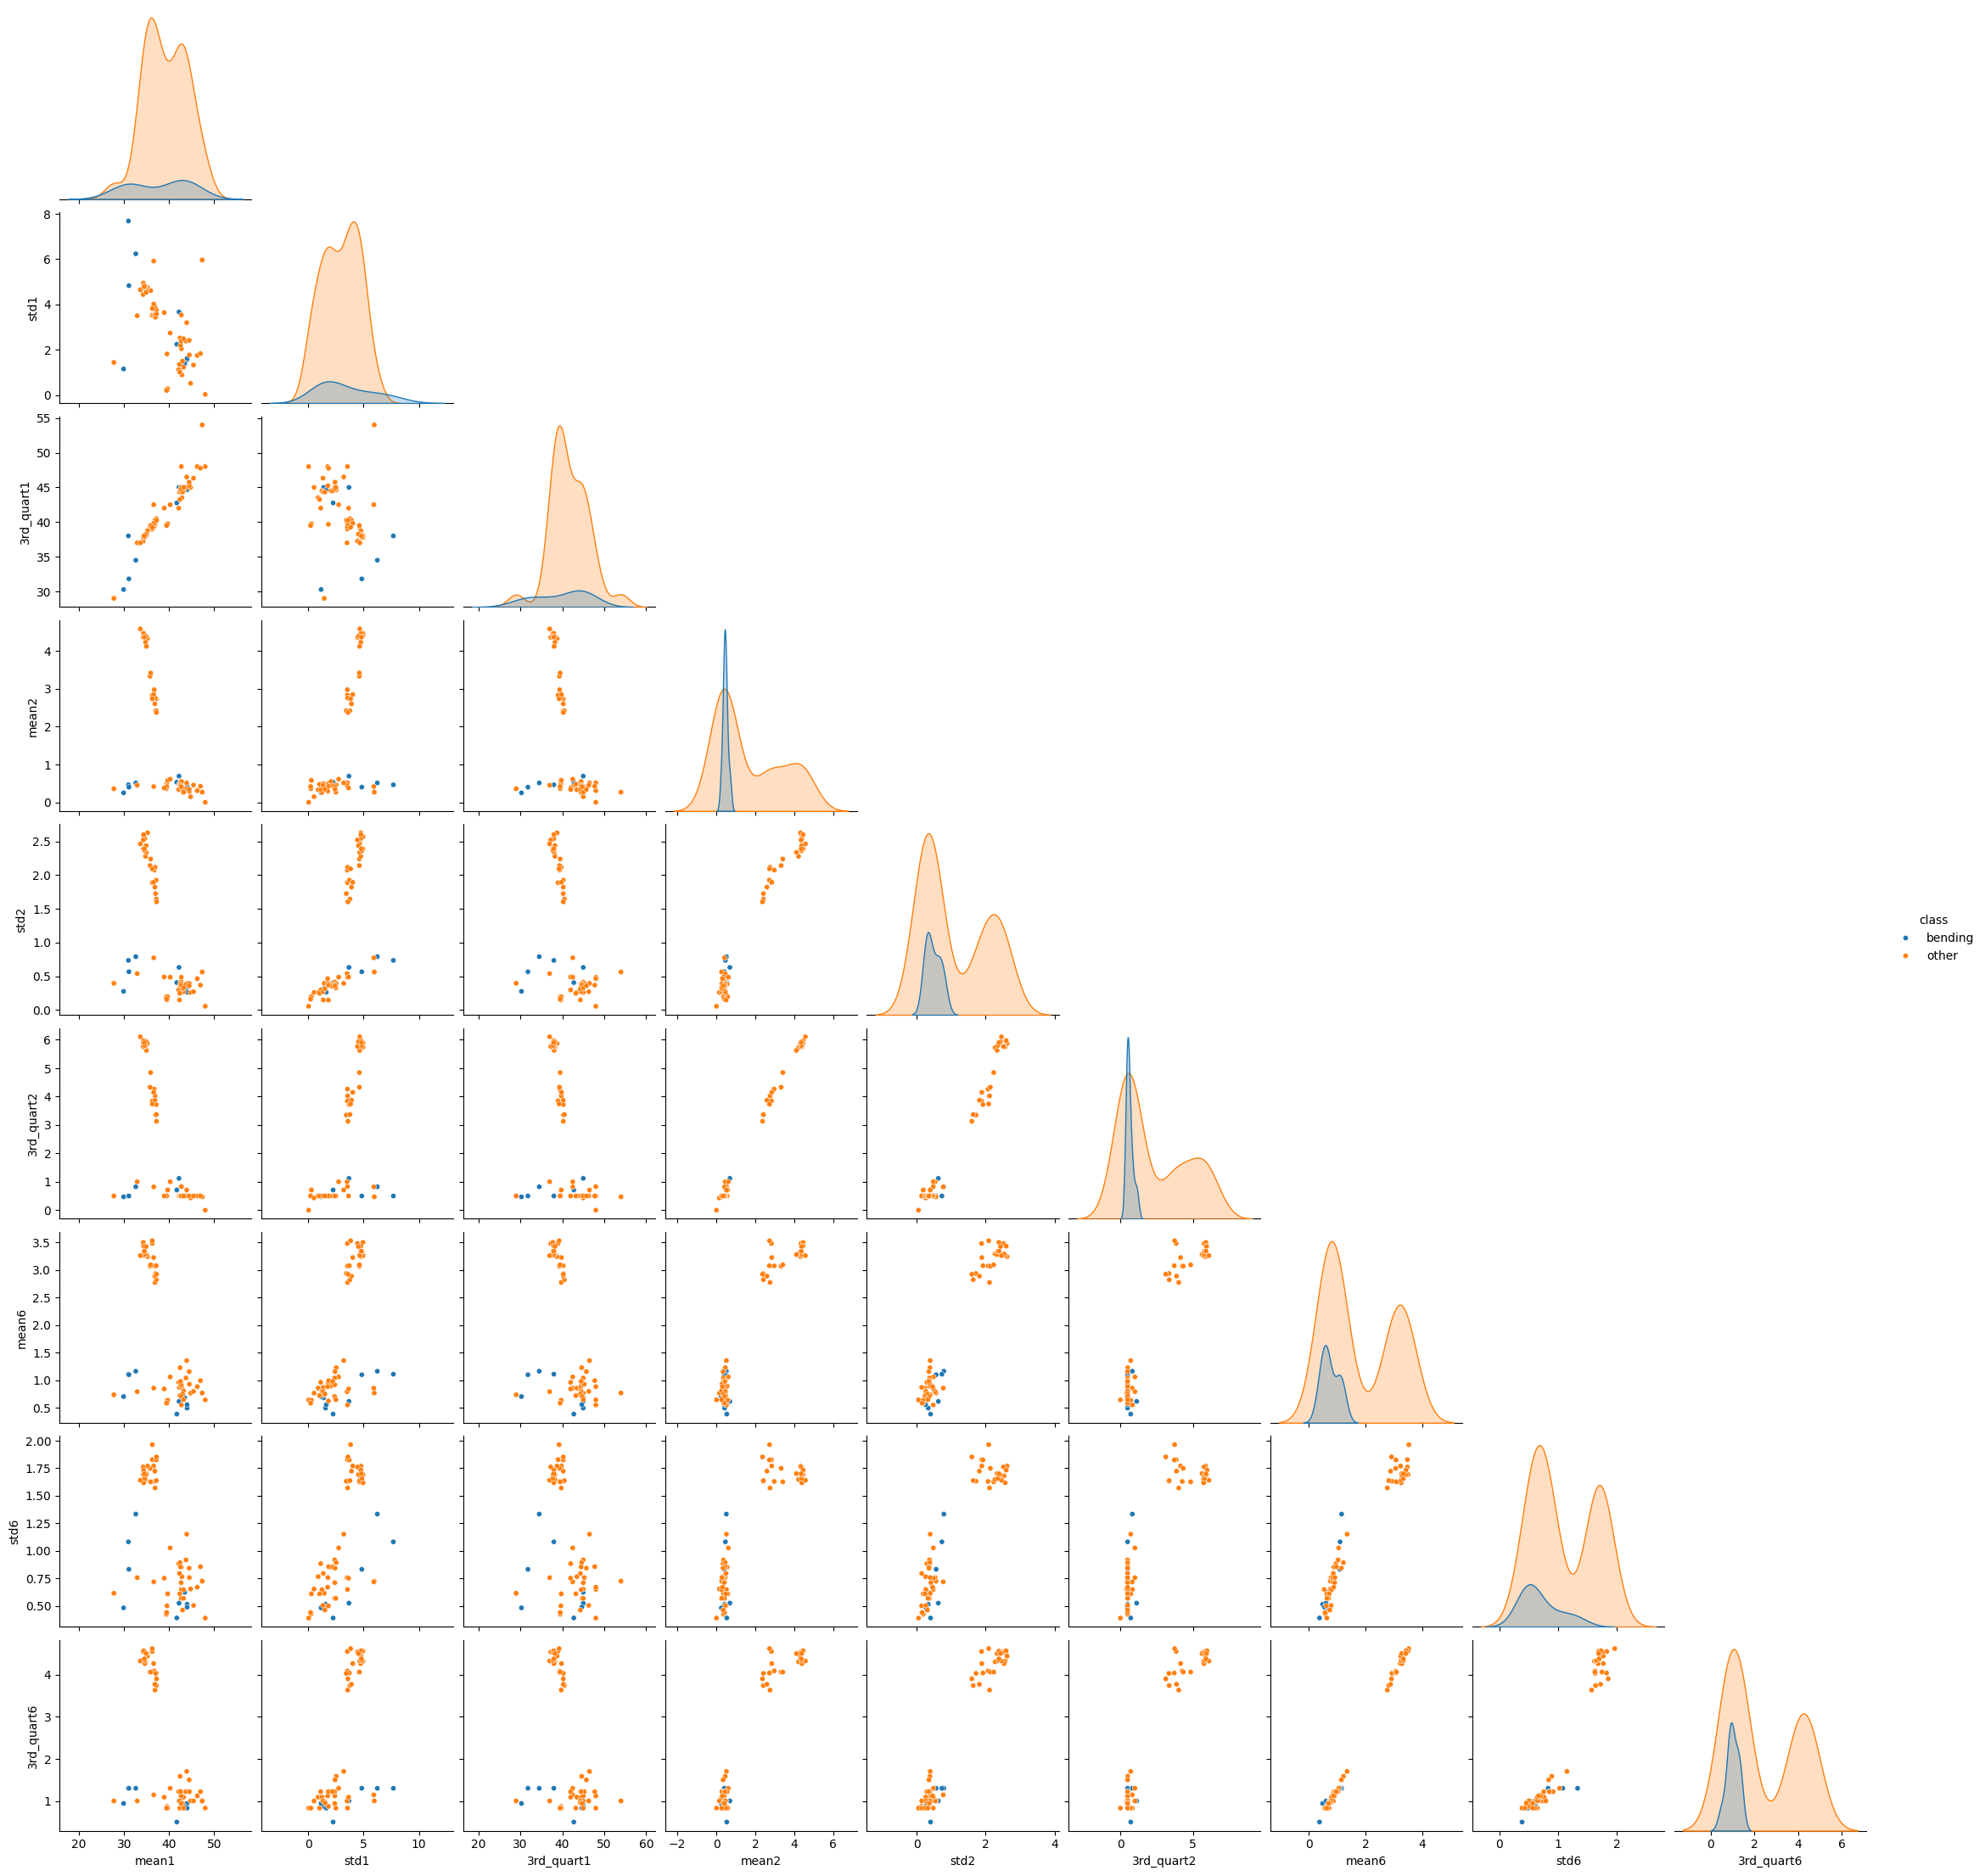

In [72]:
train_df = features[features.split == "train"]

# 9 feats mean, std, 3rd quartile for series 1 2 6
cols = [f"{stat}{k}" for k in (1,2,6) for stat in ("mean", "std", "3rd_quart")]

plot_df = train_df[cols].copy()
plot_df["class"] = train_df["activity"].str.startswith("bending").map({True: "bending", False: "other"})

print(plot_df["class"].value_counts())

sns.pairplot(plot_df, hue="class", vars=cols, corner=True, plot_kws={"s": 20})
plt.show()

Bending is not cleanly separable from the other activities using these features. Features from series 2 and 6 separate activities (cycling, walking) which have high values from static ones (sitting, lying, standing) which sit near zero. Bending falls inside the static cluster. Series 1 features (especially mean1 and std1) give partial separation, as some bending instances have lower mean1 or higher std1, but there is still overlap. The classes are also imbalanced: 9 bending vs 60 other.

#### ii. Splitted Plots

(88, 87)


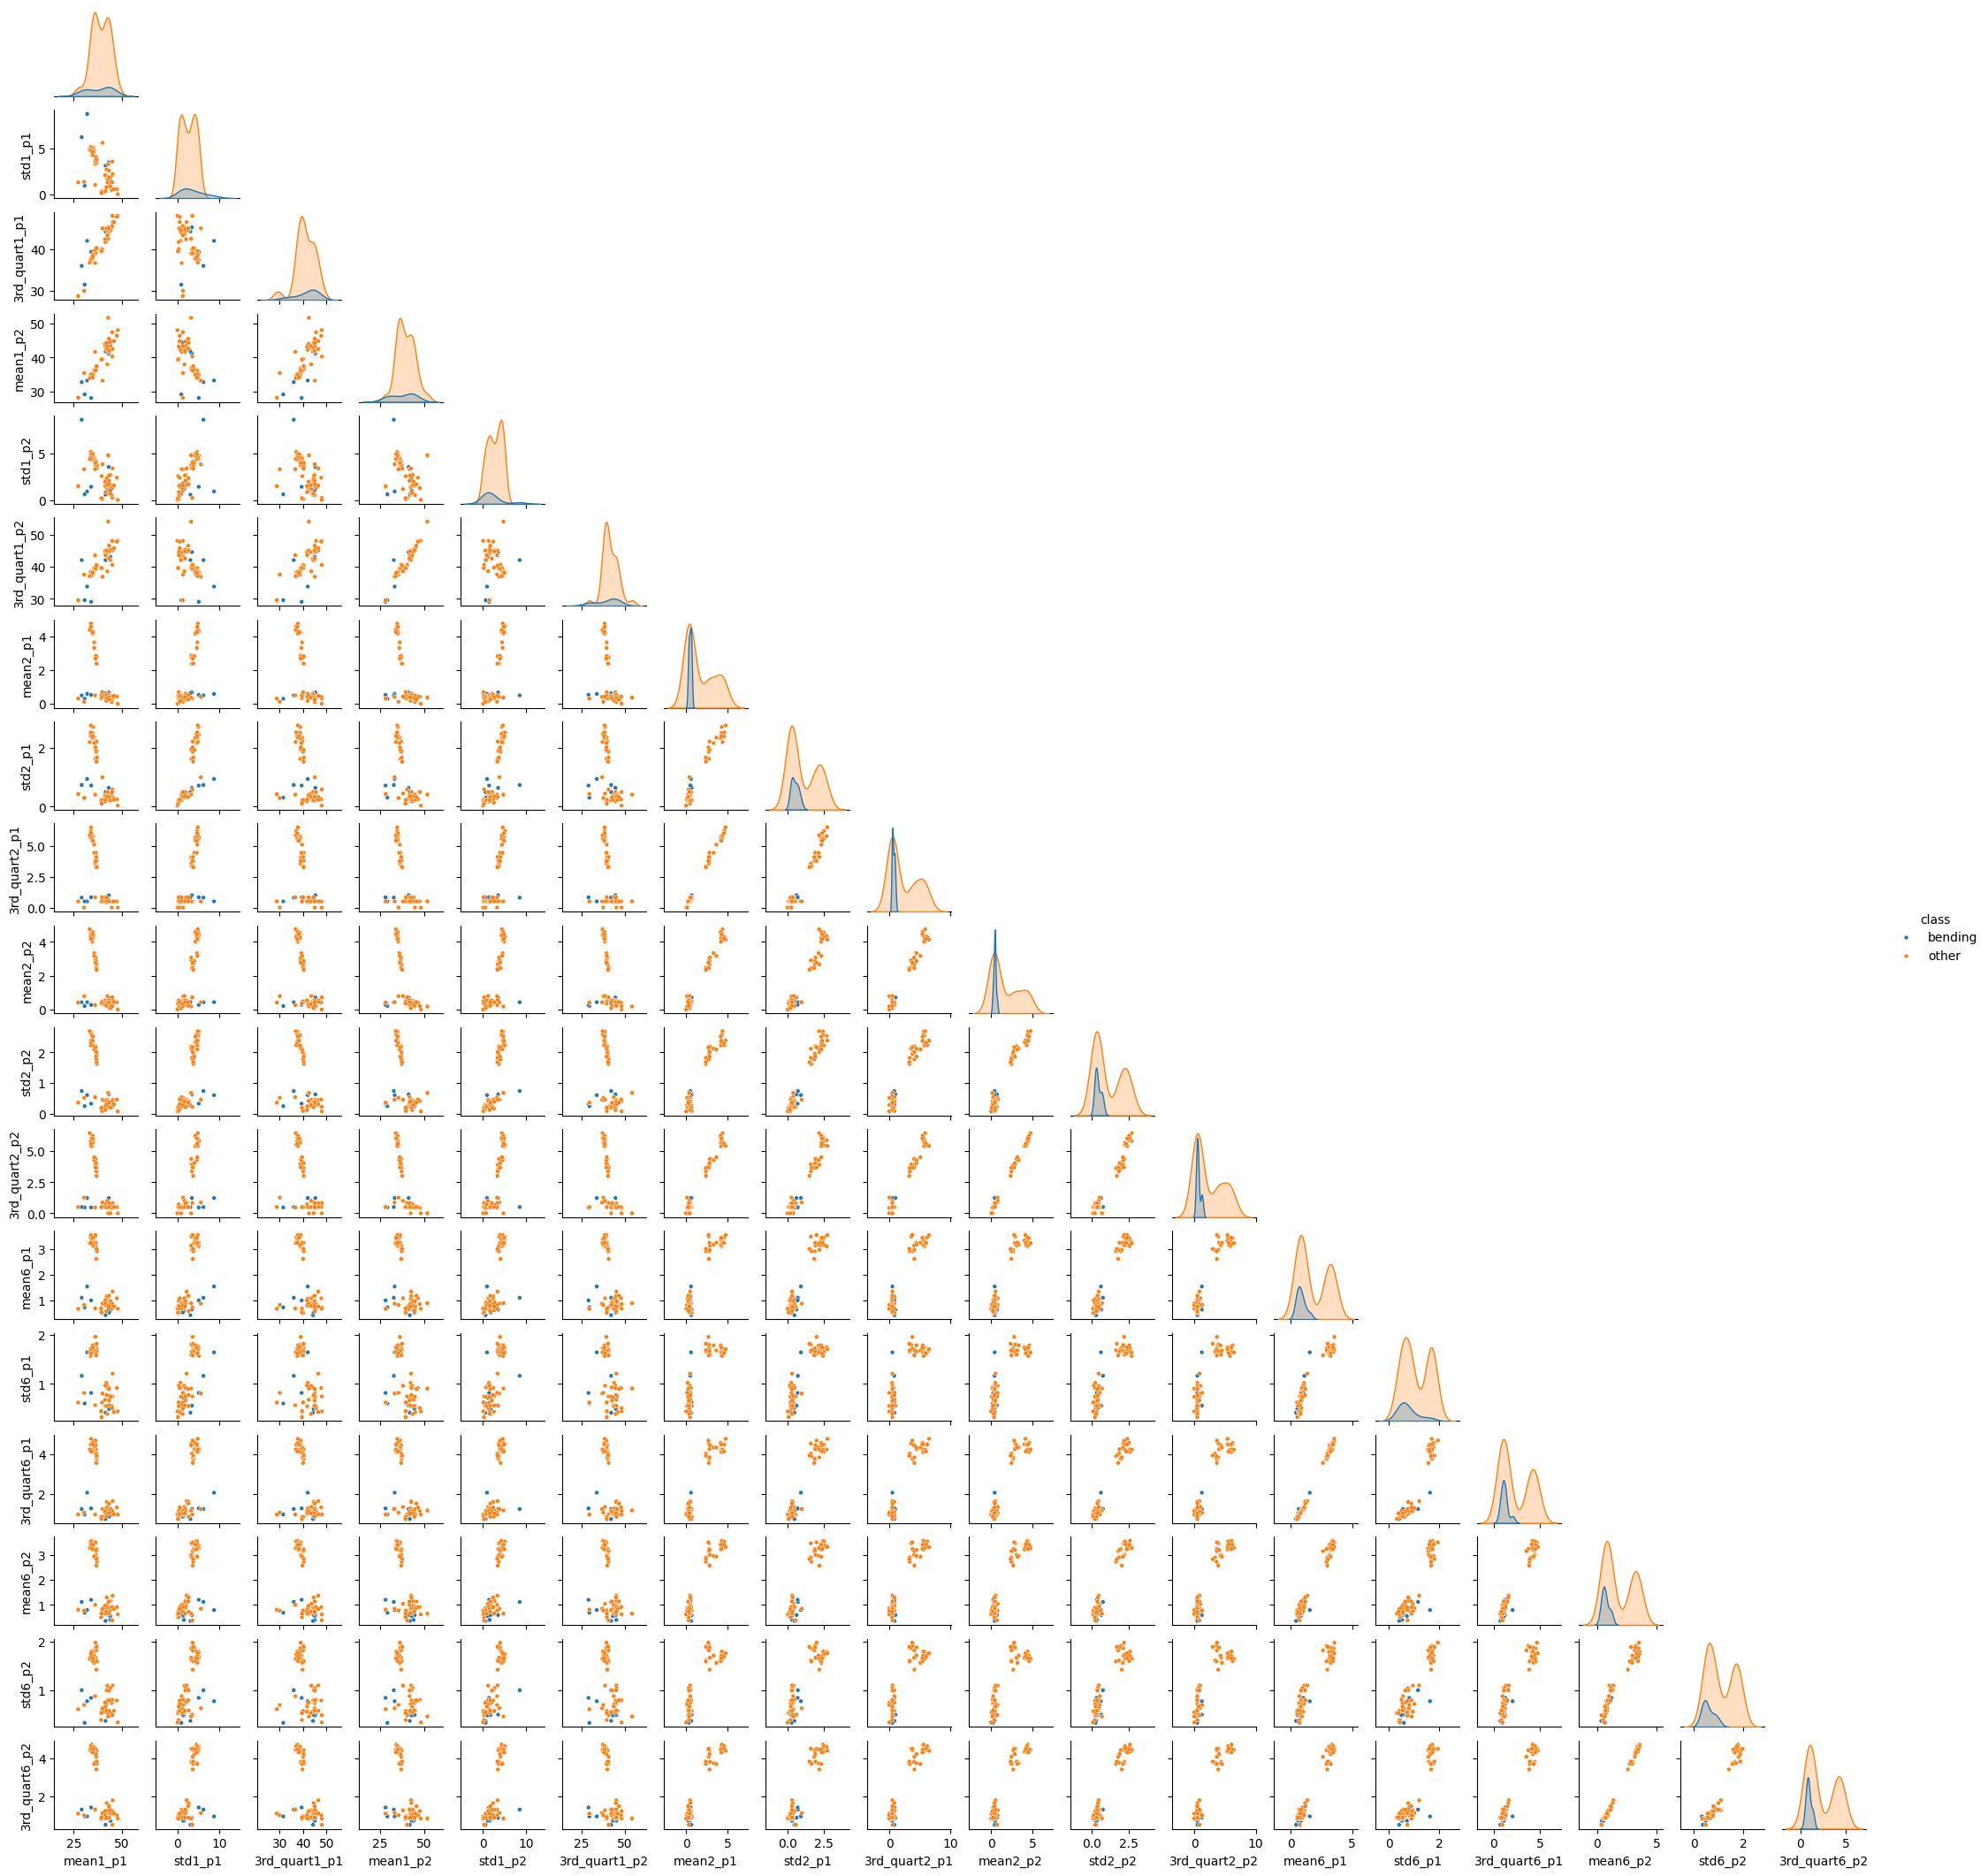

In [73]:
def extract_features_l(df, l):
    row = {}
    for i, col in enumerate(SERIES, start=1):
        parts = np.array_split(df[col].to_numpy(),l)
        for j, part in enumerate(parts, start=1):
            s = pd.Series(part)
            row[f"min{i}_p{j}"] = s.min()
            row[f"max{i}_p{j}"] = s.max()
            row[f"mean{i}_p{j}"] = s.mean()
            row[f"median{i}_p{j}"] = s.median()
            row[f"std{i}_p{j}"] = s.std()
            row[f"1st_quart{i}_p{j}"] = s.quantile(0.25)
            row[f"3rd_quart{i}_p{j}"] = s.quantile(0.75)
    return row

def build_features(l):
    rows = []
    for (act, n), df in sorted(data.items()):
        r = {"activity": act, "file": n, "split": "test" if (act,n) in test else "train"}
        r.update(extract_features_l(df, l))
        rows.append(r)
    return pd.DataFrame(rows)

f2 = build_features(2)
print(f2.shape)

train2 = f2[f2.split == "train"]
cols2 = [f"{stat}{k}_p{j}" for k in (1,2,6) for j in (1,2) for stat in ("mean", "std", "3rd_quart")]

plot_df = train2[cols2].copy()
plot_df["class"] = train2["activity"].str.startswith("bending").map({True: "bending", False: "other"})

sns.pairplot(plot_df, hue="class", vars=cols2, corner=True, plot_kws={"s": 12}, height=1.2)

There is no reasonable difference in the pairplots for the previous part. 
The same two clusters appear active activities (cycling, walking) have high values for variance in series 2 and 6 while static activities (sitting, lying, standing) sit near zero 
Bending still overlaps the static cluster on series 2 and 6 and is only partially separated from the other activities by series 1 features

The corresponding features from the two halves are strongly correlated and fall along a near-diagonal line. This shows that each activity's signal is fairly stationary over the recording, so each half carries similar information to the full series.

#### iii. Time Series Segments

In [74]:
warnings.filterwarnings("ignore")

def make_lr():
    return LogisticRegression(penalty=None, max_iter=300)

L_VALUES = range(1,21)
P_VALUES = range(1,16)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = []
for l in L_VALUES:
    fl = build_features(l)
    tr = fl[fl.split == "train"]
    X = tr.iloc[:, 3:].to_numpy()
    y = tr["activity"].str.startswith("bending").astype(int).to_numpy()

    acc = {p: [] for p in P_VALUES}
    for tr_idx, va_idx in skf.split(X,y):
        scaler = StandardScaler().fit(X[tr_idx])
        Xtr, Xva = scaler.transform(X[tr_idx]), scaler.transform(X[va_idx])

        ranking = RFE(make_lr(), n_features_to_select=1, step=0.05).fit(Xtr, y[tr_idx]).ranking_
        order = np.argsort(ranking)

        for p in P_VALUES: 
            keep = order[:p]
            model = make_lr().fit(Xtr[:, keep], y[tr_idx])
            acc[p].append(accuracy_score(y[va_idx], model.predict(Xva[:, keep])))

    for p in P_VALUES:
        results.append({"l": l, "p": p, "cv_acc": np.mean(acc[p])})
    print(f"l={l} done")

res = pd.DataFrame(results)
res.sort_values("cv_acc", ascending=False).head(10)

best = res.loc[res.cv_acc.idxmax()]
best_l, best_p = int(best.l), int(best.p)
print(f"Best l = {best_l}, p = {best_p}, CV accuracy = {best.cv_acc:.3f}")

l=1 done
l=2 done
l=3 done
l=4 done
l=5 done
l=6 done
l=7 done
l=8 done
l=9 done
l=10 done
l=11 done
l=12 done
l=13 done
l=14 done
l=15 done
l=16 done
l=17 done
l=18 done
l=19 done
l=20 done
Best l = 10, p = 3, CV accuracy = 1.000


Wrong way: run feature selection on all training data first, then cross-validate a model using only the selected features.
Bad because the selection step has already seen the validation folds. The chosen features look pretty good partly because they happened to fit these rows, so the CV acc comes out optimistically biased known as data leakage. 

Right way: Treat every step that learns from data as part of the model, and repeat it from scratch inside each fold using only that fold's training portion. In each of the 5 folds, the training portion is used to compute standardization mean and std, run RFE to select top p features, and fit the logistic regression. The held-out fold is then standardized with the training portion stats, reduced to the same selected features and used only to measure accuracy. Because the held-out fold never influences any modeling decision, the average CV accuracy is an honest estimate of performance on any unseen data.


Stratified CV: Since bending is only 9 of 69 training instances, random 5-fold splits could produce folds with no bending instances at all. Stratified K-fold keeps the class proportions the same in every fold, so each fold has both classes for training and validation. 

#### iv. Confusion Matrix

Selected features: ['1st_quart3_p4', 'min5_p9', 'max6_p8']


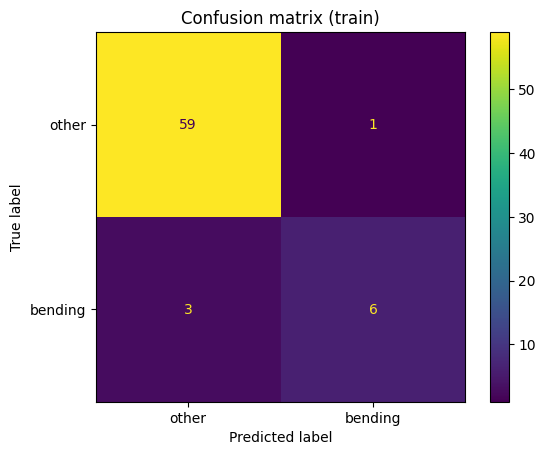

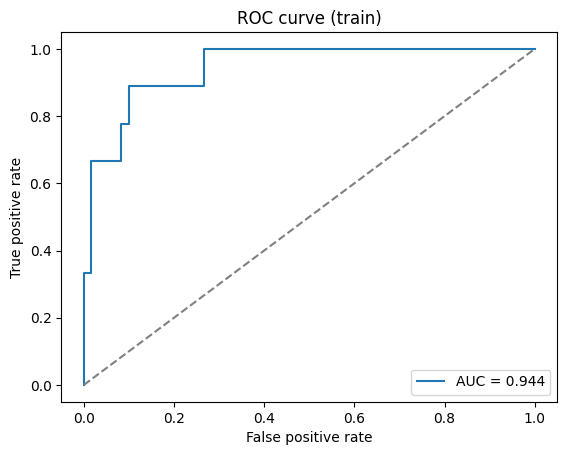

,beta,std_err,p_value
intercept,-3.6645,1.2148,0.0026
1st_quart3_p4,0.2568,0.4002,0.5210
min5_p9,1.3626,0.5653,0.0159
max6_p8,-2.2056,1.3931,0.1134


In [75]:
fl = build_features(best_l)
train_l = fl[fl.split == "train"]
feat_names = train_l.columns[3:]
X_train = train_l[feat_names].to_numpy()
y_train = train_l["activity"].str.startswith("bending").astype(int).to_numpy()

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)

rfe = RFE(make_lr(), n_features_to_select=best_p, step=0.05).fit(X_train_s, y_train)
selected = feat_names[rfe.support_]
print("Selected features:", list(selected))

X_train_sel = X_train_s[:, rfe.support_]
final_model = make_lr().fit(X_train_sel, y_train)

y_pred = final_model.predict(X_train_sel)
cm = confusion_matrix(y_train, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot()
plt.title("Confusion matrix (train)")
plt.show()

y_prob = final_model.predict_proba(X_train_sel)[:, 1]
fpr, tpr, _ = roc_curve(y_train, y_prob)
auc = roc_auc_score(y_train, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1], [0,1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (train)")
plt.legend()
plt.show()

sm_model = sm.Logit(y_train, sm.add_constant(X_train_sel)).fit(disp=0, maxiter=300)
coef_table = pd.DataFrame({
    "beta": sm_model.params,
    "std_err": sm_model.bse,
    "p_value": sm_model.pvalues,
}, index=["intercept"] + list(selected))
coef_table.round(4)


Training Accuracy (94.2%) is lower than 100% CV accuracy. Normally a model performs at least as well on the data it was trained on, so this suggests the CV score was optimistically biased since the validation folds were small.

#### v. Test Classifier

Test accuracy: 0.895
CV accuracy: 1.000
Test AUC: 0.800


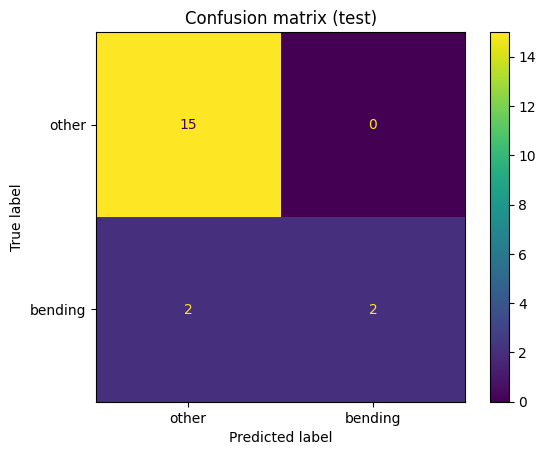

In [76]:
test_l = fl[fl.split == "test"]
X_test = test_l[feat_names].to_numpy()
y_test = test_l["activity"].str.startswith("bending").astype(int).to_numpy()

X_test_sel = scaler.transform(X_test)[:, rfe.support_]

y_test_pred = final_model.predict(X_test_sel)
y_test_prob = final_model.predict_proba(X_test_sel)[:, 1]

test_acc = accuracy_score(y_test, y_test_pred)
print(f"Test accuracy: {test_acc:.3f}")
print(f"CV accuracy: {best.cv_acc:.3f}")
print(f"Test AUC: {roc_auc_score(y_test, y_test_prob):.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred), display_labels=["other", "bending"]).plot()
plt.title("Confusion matrix (test)")
plt.show()


Test accuracy = 17/19 = 89.5% where CV accuracy = 100%. Test AUC = 0.80

Test accuracy is noticeably lower than the CV estimate, which confirms that the CV score was optimistically biased: small validation folds and selecting the best of 300 (l,p) combinations inflated it. Both test errors are bending instances misclassified as other (2 of 4 bending instances detected) meaning the model struggles with minority class consistent with the class imbalance seen in the training confusion matrix (9 bending vs 60 others)

#### vi. Separation

In [77]:
for p in (3, 5, 8, 15):
    r = RFE(make_lr(), n_features_to_select=p, step=0.05).fit(X_train_s, y_train)
    Xp = X_train_s[:, r.support_]
    m = make_lr().fit(Xp, y_train)
    train_acc = (m.predict(Xp) == y_train).mean()
    try:
        s = sm.Logit(y_train, sm.add_constant(Xp)).fit(disp=0, maxiter=300)
        print(f"p={p:2d}  train acc={train_acc:.3f}  converged={s.mle_retvals['converged']}  "
              f"max|beta|={abs(s.params).max():.1f}  max SE={s.bse.max():.1f}")
    except Exception as e:
        print(f"p={p:2d}  train acc={train_acc:.3f}  statsmodels error: {type(e).__name__}")

p= 3  train acc=0.942  converged=True  max|beta|=3.7  max SE=1.4
p= 5  train acc=0.957  converged=True  max|beta|=4.4  max SE=1.4
p= 8  train acc=1.000  converged=False  max|beta|=42.6  max SE=4382979.9
p=15  train acc=1.000  converged=False  max|beta|=28.8  max SE=12971177.3


The final model (l = 10, p = 3) is stable. It misclassifies 4 training instances , so the classes are not perfectly separated, the fit converges, and the coefficients and standard errors are reasonable. 

With more features, however, the classes become perfectly separable. At p =8 and p = 15 the model reaches 100% training accuracy, fails to converge, and has huge standard errors. This happens because there are many features (420) but only 9 bending instances. Regularization prevents this by penalizing large coefficients. 

#### vii. Imbalance

Yes. Training has 9 bending vs 60 other (13% vs 87%), and test has 4 vs 15. The confusion matrices show the effect: the model gets almost every "other" right but misses many bending instances (3 of 9 in train, 2 of 4 in test). It leans toward the majority class.

Intercept: case-control = -2.046, adjusted = -3.944
Slopes: {'1st_quart3_p4': 1.813, 'min5_p9': 1.592, 'max6_p8': -4.7}

train: accuracy = 0.884, AUC = 0.915


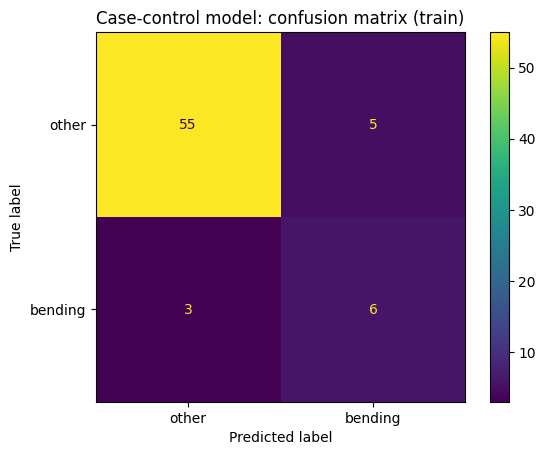

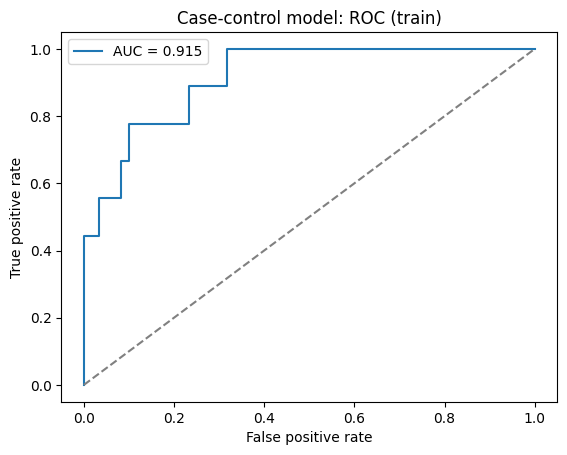


test: accuracy = 0.789, AUC = 0.850


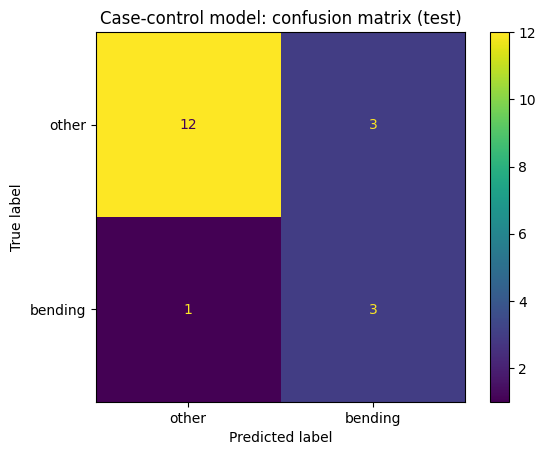

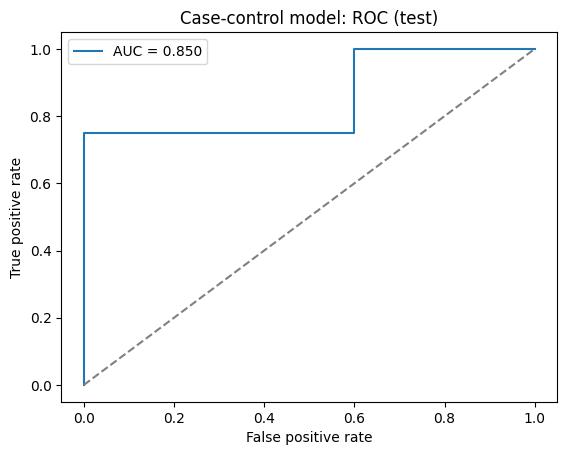

In [78]:
rng = np.random.default_rng(0)

case_idx = np.where(y_train == 1)[0]
ctrl_idx = np.where(y_train == 0)[0]
ctrl_sample = rng.choice(ctrl_idx, size=len(case_idx), replace=False)
cc_idx = np.concatenate([case_idx, ctrl_sample])

cc_model = make_lr().fit(X_train_sel[cc_idx], y_train[cc_idx])

pi = y_train.mean()
pi_tilde = y_train[cc_idx].mean()
adjustment = np.log(pi/ (1-pi)) - np.log(pi_tilde/ (1 - pi_tilde))

beta0_adj = cc_model.intercept_[0] + adjustment
betas = cc_model.coef_[0]
print(f"Intercept: case-control = {cc_model.intercept_[0]:.3f}, adjusted = {beta0_adj:.3f}")
print(f"Slopes:", dict(zip(selected, betas.round(3))))

def predict_prob(X):
    return 1 / (1 + np.exp(-(X @ betas + beta0_adj)))

for X_,y_, name in [(X_train_sel, y_train, "train"), (X_test_sel, y_test, "test")]:
    prob = predict_prob(X_)
    pred = (prob >= 0.5).astype(int)
    print(f"\n{name}: accuracy = {(pred == y_).mean():.3f}, AUC = {roc_auc_score(y_,prob):.3f}")
    ConfusionMatrixDisplay(confusion_matrix(y_, pred), display_labels=["other", "bending"]).plot()
    plt.title(f"Case-control model: confusion matrix ({name})")
    plt.show()

    fpr, tpr, _ = roc_curve(y_, prob)
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_, prob):.3f}")
    plt.plot([0,1], [0,1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"Case-control model: ROC ({name})")
    plt.legend()
    plt.show()


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [79]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

C_GRID = np.logspace(-2,2,20)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def make_l1_pipe(C=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000))
    ])

l1_results = []
for l in range(1,21):
    fl = build_features(l)
    tr = fl[fl.split == "train"]
    X = tr.iloc[:, 3:].to_numpy()
    y = tr["activity"].str.startswith("bending").astype(int).to_numpy()

    gs = GridSearchCV(make_l1_pipe(), {"lr__C": C_GRID}, cv=skf, scoring="accuracy").fit(X, y)
    l1_results.append({"l": l, "best_C": gs.best_params_["lr__C"], "cv_acc": gs.best_score_})
    print(f"l={l} done")

l1_res = pd.DataFrame(l1_results)
l1_res.sort_values("cv_acc", ascending=False).head(10)

l=1 done
l=2 done
l=3 done
l=4 done
l=5 done
l=6 done
l=7 done
l=8 done
l=9 done
l=10 done
l=11 done
l=12 done
l=13 done
l=14 done
l=15 done
l=16 done
l=17 done
l=18 done
l=19 done
l=20 done


,l,best_C,cv_acc
0,1,0.483293,0.985714
19,20,8.858668,0.985714
2,3,0.297635,0.971429
1,2,14.384499,0.971429
18,19,0.784760,0.971429
17,18,0.483293,0.971429
13,14,1.274275,0.971429
12,13,1.274275,0.971429
16,17,23.357215,0.970330
11,12,0.483293,0.970330


Best l = 1, C = 0.483, CV accuracy = 0.986
Features kept: 4 of 42: ['3rd_quart1_p1', 'min5_p1', 'max5_p1', '1st_quart6_p1']
train: accuracy = 0.986, AUC = 0.998


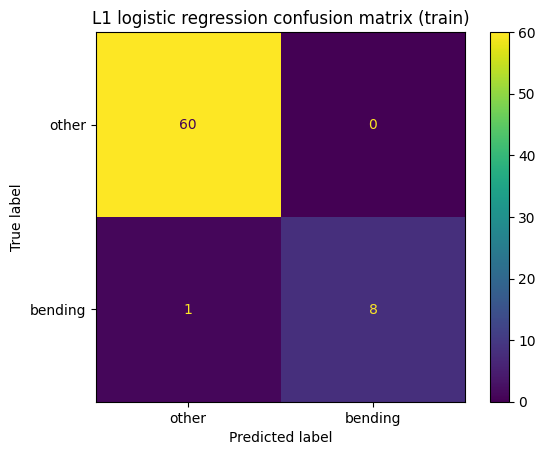

test: accuracy = 1.000, AUC = 1.000


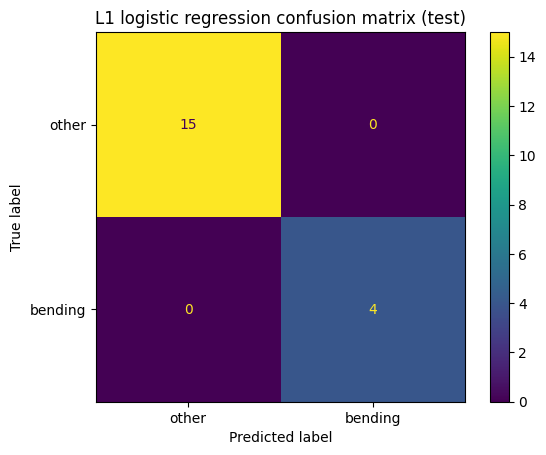

In [80]:
best_l1 = l1_res.loc[l1_res.cv_acc.idxmax()]
l_l1, C_l1 = int(best_l1.l), best_l1.best_C
print(f"Best l = {l_l1}, C = {C_l1:.3f}, CV accuracy = {best_l1.cv_acc:.3f}")

fl = build_features(l_l1)
tr, te = fl[fl.split == "train"], fl[fl.split == "test"]
X_tr, X_te = tr.iloc[:, 3:].to_numpy(), te.iloc[:, 3:].to_numpy()
y_tr = tr["activity"].str.startswith("bending").astype(int).to_numpy()
y_te = te["activity"].str.startswith("bending").astype(int).to_numpy()

l1_model = make_l1_pipe(C_l1).fit(X_tr, y_tr)

coefs = l1_model["lr"].coef_[0]
print(f"Features kept: {(coefs != 0).sum()} of {len(coefs)}:", list(tr.columns[3:][coefs != 0]))

for X_, y_, name in [(X_tr, y_tr, "train"), (X_te, y_te, "test")]:
    pred = l1_model.predict(X_)
    prob = l1_model.predict_proba(X_)[:, 1]
    print(f"{name}: accuracy = {accuracy_score(y_, pred):.3f}, AUC = {roc_auc_score(y_, prob):.3f}")
    ConfusionMatrixDisplay(confusion_matrix(y_,pred), display_labels=["other", "bending"]).plot()
    plt.title(f"L1 logistic regression confusion matrix ({name})")
    plt.show()

The best pair was l = 1, C = 0.483 with a CV accuracy of 98.6%

#### ii. Comparison

The L1 model's CV estimate 98.6% closely matches its test accuracy (100%), while the RFE model's 100% CV accuracy dropped to 89.5% (test error 10.5%) on the test set, suggesting that L1 generalizes more reliably, performing better.

L1 is also easier to implement because feature selection and fitting happen in one step so there is no need to compute p-values, prune features and refit or run RFE manually inside each fold. A pipeline with gridsearchCV tunes C and keeps standardization inside each fold automatically. The L1 penalty also keeps the coefficients finite even when the classes are separable, which avoids the convergence problem.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [81]:
C_GRID_MULTI = np.logspace(-1,2,6)


def make_multi_pipe(C=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=500, tol=1e-3))
    ])

multi_results = []
for l in range(1,21):
    fl = build_features(l)
    tr = fl[fl.split == "train"]
    X = tr.iloc[:, 3:].to_numpy()
    y = tr["activity"].to_numpy()

    gs = GridSearchCV(make_multi_pipe(), {"lr__C": C_GRID_MULTI}, cv=skf, scoring="accuracy", n_jobs=-1).fit(X, y)
    multi_results.append({"l": l, "best_C": gs.best_params_["lr__C"], "cv_acc": gs.best_score_})
    print(f"l={l} done")

multi_res = pd.DataFrame(multi_results)
multi_res.sort_values("cv_acc", ascending=False).head()

l=1 done


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


l=2 done


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


l=3 done


...

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The ma

l=19 done


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The ma

l=20 done


,l,best_C,cv_acc
0,1,1.584893,0.897802
1,2,1.584893,0.868132
5,6,6.309573,0.852747
16,17,0.398107,0.852747
2,3,6.309573,0.839560


Best l = 1, C = 1.585, CV accuracy = 0.898
Test Error = 0.105 (accuracy = 0.895)


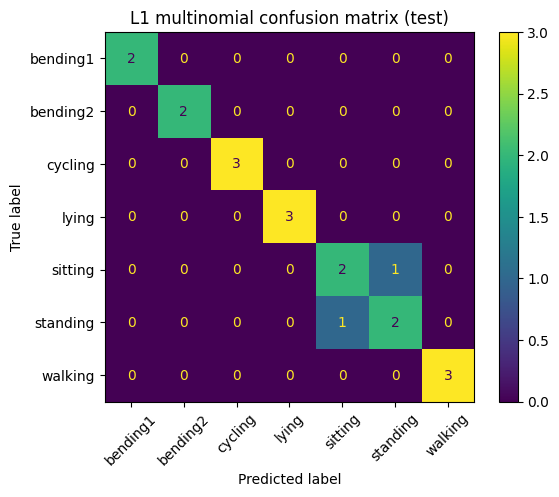

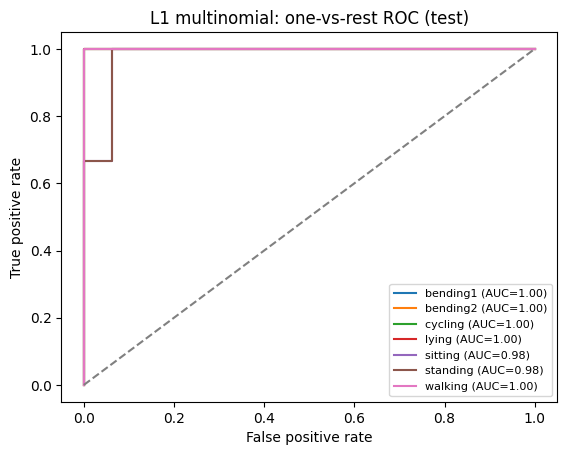

In [82]:
from sklearn.preprocessing import label_binarize

best_m = multi_res.loc[multi_res.cv_acc.idxmax()]
l_m, C_m = int(best_m.l), best_m.best_C
print(f"Best l = {l_m}, C = {C_m:.3f}, CV accuracy = {best_m.cv_acc:.3f}")

fl = build_features(l_m)
tr, te = fl[fl.split == "train"], fl[fl.split == "test"]
X_tr, y_tr = tr.iloc[:, 3:].to_numpy(), tr["activity"].to_numpy()
X_te, y_te = te.iloc[:, 3:].to_numpy(), te["activity"].to_numpy()

multi_model = make_multi_pipe(C_m).fit(X_tr, y_tr)
classes = multi_model.classes_
y_te_pred = multi_model.predict(X_te)

test_err = 1 - accuracy_score(y_te, y_te_pred)
print(f"Test Error = {test_err:.3f} (accuracy = {1 - test_err:.3f})")

ConfusionMatrixDisplay(confusion_matrix(y_te, y_te_pred, labels=classes), display_labels=classes).plot(xticks_rotation=45)
plt.title("L1 multinomial confusion matrix (test)")
plt.show()

probs = multi_model.predict_proba(X_te)
Y_bin = label_binarize(y_te, classes=classes)
for k, cls in enumerate(classes): 
    fpr, tpr, _ = roc_curve(Y_bin[:, k], probs[:, k])
    plt.plot(fpr, tpr, label=f"{cls} (AUC={roc_auc_score(Y_bin[:, k], probs[:, k]):.2f})")
plt.plot([0,1], [0,1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("L1 multinomial: one-vs-rest ROC (test)")
plt.legend(fontsize=8)
plt.show()


#### ii. Naive Bayes

Gaussian NB: best l = 1, CV acc = 0.854, test error = 0.105


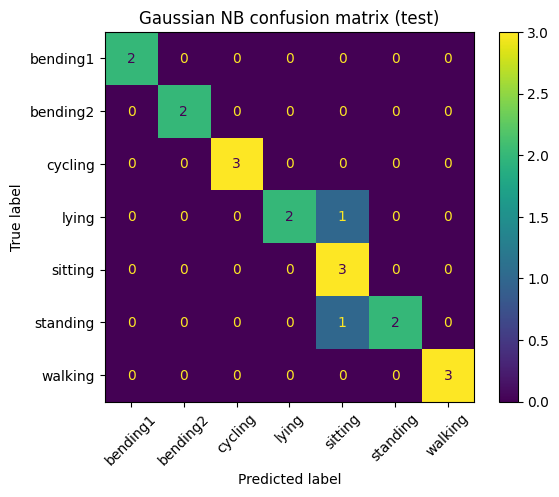

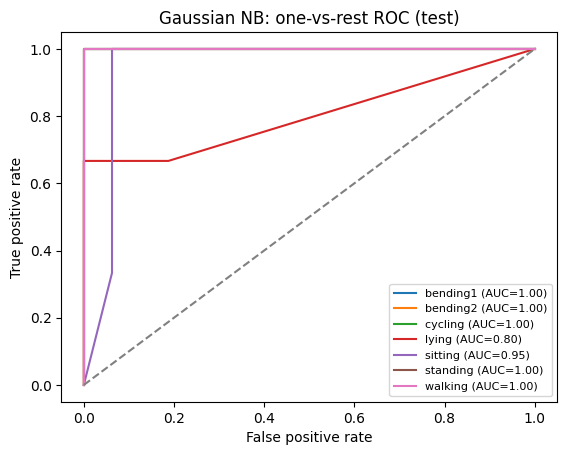

Multinomial NB: best l = 2, CV acc = 0.738, test error = 0.211


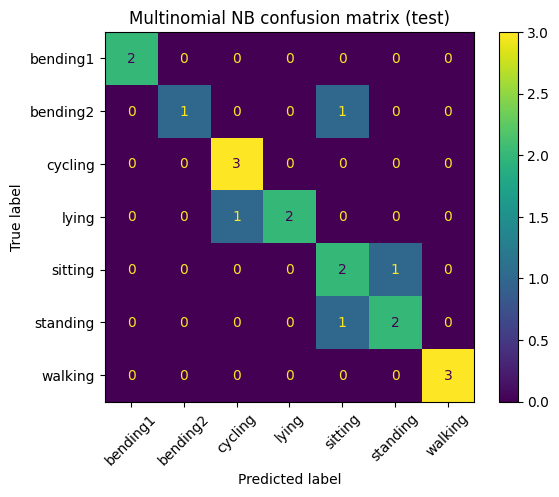

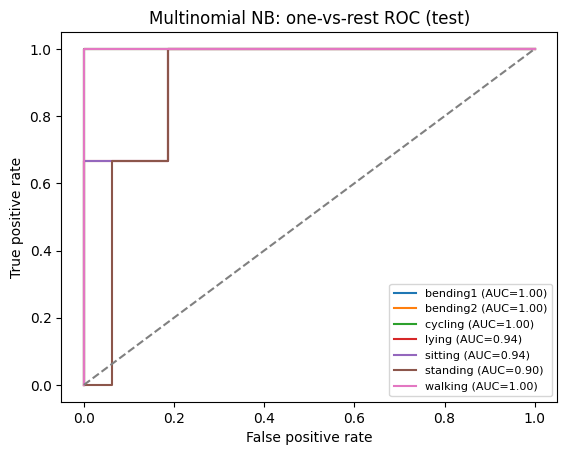

,model,best_l,cv_acc,test_error
0,Gaussian NB,1,0.854,0.105
1,Multinomial NB,2,0.738,0.211


In [83]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

nb_models = {
    "Gaussian NB": lambda: GaussianNB(),
    "Multinomial NB": lambda: Pipeline([("minmax", MinMaxScaler()), ("nb", MultinomialNB())]),
}

nb_summary = []
for name, make_model in nb_models.items():
    cv_scores = []
    for l in range(1,21):
        fl = build_features(l)
        tr = fl[fl.split == "train"]
        X, y = tr.iloc[:, 3:].to_numpy(), tr["activity"].to_numpy()
        cv_scores.append(cross_val_score(make_model(), X,y, cv=skf).mean())
    best_l_nb = int(np.argmax(cv_scores)) + 1

    fl = build_features(best_l_nb)
    tr, te = fl[fl.split == "train"], fl[fl.split == "test"]
    X_tr, y_tr = tr.iloc[:, 3:].to_numpy(), tr["activity"].to_numpy()
    X_te, y_te = te.iloc[:, 3:].to_numpy(), te["activity"].to_numpy()

    model = make_model().fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    test_err = 1 - accuracy_score(y_te, y_pred)
    nb_summary.append({"model": name, "best_l": best_l_nb, "cv_acc": max(cv_scores), "test_error": test_err})
    print(f"{name}: best l = {best_l_nb}, CV acc = {max(cv_scores):.3f}, test error = {test_err:.3f}")

    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=model.classes_), display_labels=model.classes_).plot(xticks_rotation=45)
    
    plt.title(f"{name} confusion matrix (test)")
    plt.show()

    probs = model.predict_proba(X_te)
    Y_bin = label_binarize(y_te, classes=model.classes_)
    for k, cls in enumerate(model.classes_): 
        fpr, tpr, _ = roc_curve(Y_bin[:, k], probs[:, k])
        plt.plot(fpr, tpr, label=f"{cls} (AUC={roc_auc_score(Y_bin[:, k], probs[:, k]):.2f})")
    plt.plot([0,1], [0,1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{name}: one-vs-rest ROC (test)")
    plt.legend(fontsize=8)
    plt.show()

pd.DataFrame(nb_summary).round(3)

#### iii. Comparison

Gaussian NB performed better than Multinomal. Gaussian NB misclassified only 2 test instances (one lying and one standing, both predicted as sitting). Multinomial NB made 4 errors (bending2-> siting, lying -> cycling, sitting <-> standing)

Gaussian NB assumes each feature is normally distributed within each class, which suits continuous summary statistics like means, stds, quartiles. Multinomial NB is deisgned for count data so it fits these continuous features poorly.

L1 multinomial regression is the best method as it ties Gaussian NB on test error, but it has higher CV accuracy and AUC. 

## 3. ISLR 4.8.3

In notebook folder marked as ISLR4.8.3.pdf file

## 4. ISLR 4.8.7

In [84]:
num = 0.8 *np.exp(-(4-10)**2/72)
den = num + 0.2 * np.exp(-(4 - 0)**2/72)

print(f"{num/den:.3f} chance dividend is issued by the company")



0.752 chance dividend is issued by the company


## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9